In [144]:
import pandas as pd

df = pd.read_csv("dataset.csv")

df.head(10)

,study_hours,attendance,previous_score,pass
0,6.5,71.8,86.3,0
1,1.6,74.4,53.6,0
2,5.7,44.7,71.1,0
3,5.3,96.7,78.6,0
4,11.2,60.4,96.2,1
5,2.2,61.2,66.4,0
6,10.9,74.1,82.5,1
7,3.8,92.3,99.4,0
8,8.8,74.2,82.4,1
9,11.0,63.7,100.0,1


In [145]:
X = df[["study_hours", "attendance", "previous_score"]]
y = df["pass"]

display(X.head())

,study_hours,attendance,previous_score
0,6.5,71.8,86.3
1,1.6,74.4,53.6
2,5.7,44.7,71.1
3,5.3,96.7,78.6
4,11.2,60.4,96.2


In [146]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

X_norm = scaler.fit_transform(X)

norm_df = pd.DataFrame(X_norm, columns=X.columns)
display(norm_df.head())
display(norm_df.max())
display(norm_df.min())

,study_hours,attendance,previous_score
0,0.500000,0.566154,0.807854
1,0.046296,0.606154,0.349229
2,0.425926,0.149231,0.594670
3,0.388889,0.949231,0.699860
4,0.935185,0.390769,0.946704


study_hours       1.0
attendance        1.0
previous_score    1.0
dtype: float64

study_hours       0.0
attendance        0.0
previous_score    0.0
dtype: float64

In [147]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_st = scaler.fit_transform(X)

st_df = pd.DataFrame(X_st, columns=X.columns)
display(st_df.head())
display(st_df.describe())

,study_hours,attendance,previous_score
0,0.032441,-0.075356,0.363915
1,-1.467176,0.119400,-1.905174
2,-0.212395,-2.105314,-0.690830
3,-0.334812,1.789809,-0.170397
4,1.470849,-0.929286,1.050887


,study_hours,attendance,previous_score
count,2.500000e+02,2.500000e+02,2.500000e+02
mean,-2.486900e-17,2.060574e-16,-8.562040e-16
std,1.002006e+00,1.002006e+00,1.002006e+00
min,-1.620198e+00,-2.831904e+00,-3.633013e+00
25%,-8.780410e-01,-7.420208e-01,-7.810384e-01
50%,3.244069e-02,1.827711e-02,3.777651e-02
75%,8.817135e-01,6.643431e-01,9.415956e-01
max,1.685080e+00,2.036999e+00,1.314573e+00


In [148]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3,
    random_state=42,
    stratify=y
)

In [149]:
raw_knn = KNeighborsClassifier(n_neighbors=3)
raw_knn.fit(X_train,y_train)
raw_pred = raw_knn.predict(X_test)
display(raw_pred)

array([1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0,
       1, 0, 0, 1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1,
       0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0,
       0, 0, 1, 1, 1, 1, 0, 0, 0])

In [150]:
# norm knn
minmax = MinMaxScaler()

X_train_norm = minmax.fit_transform(X_train)
X_test_norm = minmax.transform(X_test)

knn_norm = KNeighborsClassifier(n_neighbors=3)

knn_norm.fit(X_train_norm,y_train)

pred_norm = knn_norm.predict(X_test_norm)
display(pred_norm)

array([1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0,
       1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1,
       0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 1, 0, 1, 0, 1,
       0, 1, 1, 1, 1, 1, 0, 0, 0])

In [151]:
standard = StandardScaler()

X_train_std = standard.fit_transform(X_train)
X_test_std = standard.transform(X_test)

knn_std = KNeighborsClassifier(n_neighbors=3)

knn_std.fit(X_train_std, y_train)

pred_std = knn_std.predict(X_test_std)
display(pred_std)

array([1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0,
       1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1,
       0, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 1, 1, 0, 1, 0, 1,
       0, 1, 1, 1, 1, 1, 0, 0, 0])

In [152]:
print("Raw | Accuracy:", accuracy_score(y_test, raw_pred))
print("Norm | Accuracy:", accuracy_score(y_test, pred_norm))
print("STD | Accuracy:", accuracy_score(y_test, pred_std))

Raw | Accuracy: 0.8133333333333334
Norm | Accuracy: 0.8666666666666667
STD | Accuracy: 0.8933333333333333


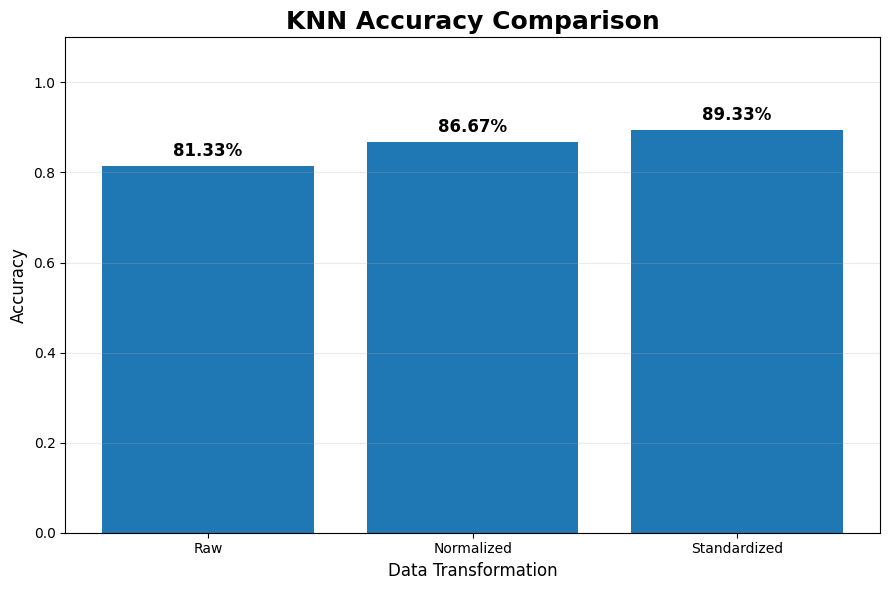

    Actual  Raw KNN  Normalized KNN  Standardized KNN
0        1        1               1                 1
1        0        0               0                 0
2        0        0               0                 0
3        0        0               0                 0
4        0        0               0                 0
5        0        1               1                 1
6        1        1               1                 1
7        1        1               1                 1
8        1        1               1                 1
9        1        1               1                 1
10       0        0               0                 0
11       1        1               1                 1
12       0        0               0                 0
13       0        0               0                 0
14       1        1               0                 1


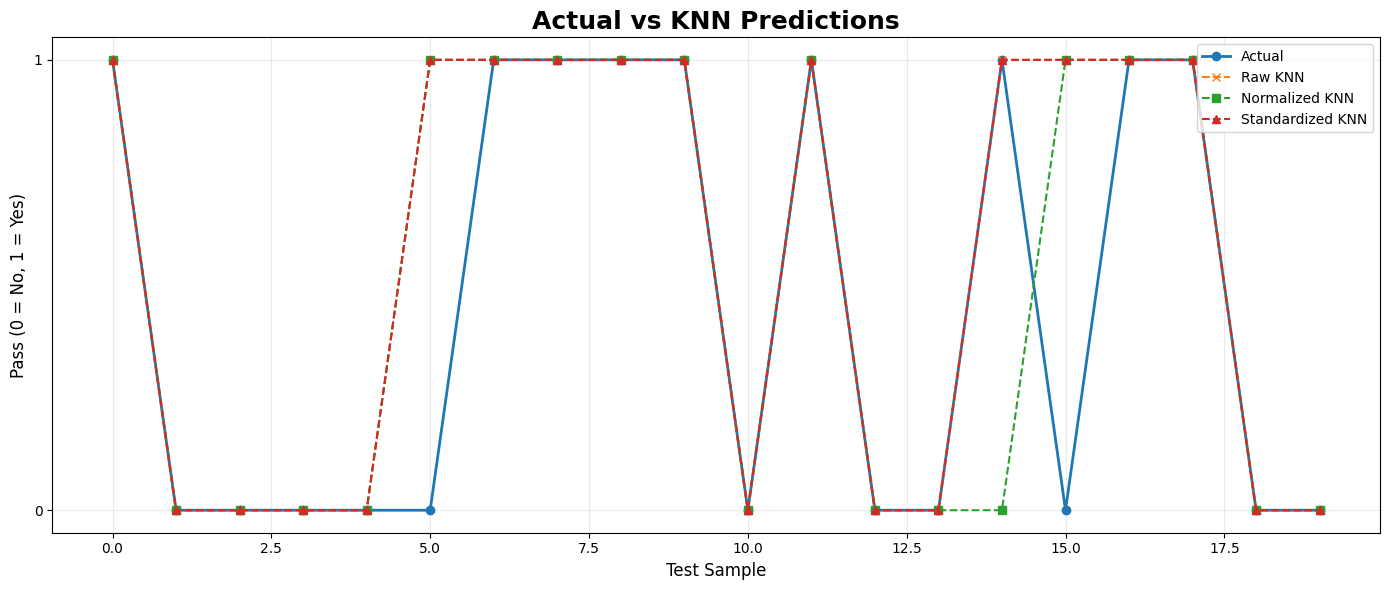


FINAL KNN PERFORMANCE
Raw KNN          : 81.33%
Normalized KNN   : 86.67%
Standardized KNN : 89.33%

Best Method: Standardized
Best Accuracy: 89.33%


In [153]:
import matplotlib.pyplot as plt
import numpy as np

# ============================================================
# 1. Calculate Accuracy
# ============================================================

raw_accuracy = accuracy_score(y_test, raw_pred)
norm_accuracy = accuracy_score(y_test, pred_norm)
std_accuracy = accuracy_score(y_test, pred_std)


# ============================================================
# 2. Accuracy Comparison
# ============================================================

methods = [
    "Raw",
    "Normalized",
    "Standardized"
]

accuracies = [
    raw_accuracy,
    norm_accuracy,
    std_accuracy
]

plt.figure(figsize=(9, 6))

bars = plt.bar(methods, accuracies)

for bar, accuracy in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.015,
        f"{accuracy:.2%}",
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight="bold"
    )

plt.title(
    "KNN Accuracy Comparison",
    fontsize=18,
    fontweight="bold"
)

plt.xlabel(
    "Data Transformation",
    fontsize=12
)

plt.ylabel(
    "Accuracy",
    fontsize=12
)

plt.ylim(0, 1.1)

plt.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()
plt.show()


# ============================================================
# 3. Prediction Comparison
# ============================================================

comparison_df = pd.DataFrame({
    "Actual": y_test.values,
    "Raw KNN": raw_pred,
    "Normalized KNN": pred_norm,
    "Standardized KNN": pred_std
})

print(comparison_df.head(15))


# ============================================================
# 4. Plot Predictions
# ============================================================

n = min(20, len(y_test))

x = np.arange(n)

plt.figure(figsize=(14, 6))

plt.plot(
    x,
    y_test.values[:n],
    marker="o",
    linewidth=2,
    label="Actual"
)

plt.plot(
    x,
    raw_pred[:n],
    marker="x",
    linestyle="--",
    label="Raw KNN"
)

plt.plot(
    x,
    pred_norm[:n],
    marker="s",
    linestyle="--",
    label="Normalized KNN"
)

plt.plot(
    x,
    pred_std[:n],
    marker="^",
    linestyle="--",
    label="Standardized KNN"
)

plt.title(
    "Actual vs KNN Predictions",
    fontsize=18,
    fontweight="bold"
)

plt.xlabel(
    "Test Sample",
    fontsize=12
)

plt.ylabel(
    "Pass (0 = No, 1 = Yes)",
    fontsize=12
)

plt.yticks([0, 1])

plt.legend()

plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()


# ============================================================
# 5. Final Result
# ============================================================

print("\n" + "=" * 50)
print("FINAL KNN PERFORMANCE")
print("=" * 50)

print(f"Raw KNN          : {raw_accuracy:.2%}")
print(f"Normalized KNN   : {norm_accuracy:.2%}")
print(f"Standardized KNN : {std_accuracy:.2%}")

best_method = methods[np.argmax(accuracies)]

print("\nBest Method:", best_method)
print(f"Best Accuracy: {max(accuracies):.2%}")